# Robotics & Reinforcement Learning กับ Jev (TypeSafe System One)

Jev ไม่ใช่ LLM ที่ generate ข้อความ — มันตอบ **คำถามแบบมีตัวเลือก** (`choice` / `noul` / `score`) พร้อม probability ในเวลาราว 150–400 ms
จึงเหมาะเป็น "สามัญสำนึกที่โปรแกรมเรียกได้" (programmable common sense) ในลูปควบคุมหุ่นยนต์และ agent

**หลักการออกแบบของ notebook นี้** (จาก [Jev 1.13 jaggedness](https://docs.typesafe.ai/model-jaggedness/jev-1.13.md))

| งาน | ใครทำ |
|:--|:--|
| geometry, ระยะทาง, physics, path planning, นับ, คำนวณ reward | **โค้ด** |
| แปลงตัวเลข/พิกัดเป็นคำ ("ทางเหนือ, ไกล", "มีลาวา") ก่อนส่งให้ Jev | **โค้ด** |
| เข้าใจคำสั่ง, เลือก skill/วัตถุ, ตัดสินความเสี่ยง, เลือก action, ให้คะแนน trajectory | **Jev** |
| ตัดสินใจสุดท้ายจาก probability + threshold, fallback ให้คน | **โค้ด** |

ข้อจำกัดที่ต้องรู้: Jev รับ **text เท่านั้น** (ไม่มีรูป — ส่วน A8 จึงใช้ Clef ที่ API หน้าตาเดียวกันแทน), ภาษาอังกฤษแม่นที่สุด

| ส่วน | โจทย์ |
|:--|:--|
| **A. Robotics** | A1 คำสั่งภาษาคน → เรียก skill (function calling) · A2 ชี้วัตถุจากคำบรรยาย (grounding) · A3 safety gate ก่อนขยับแขน · A4 task planner แบบ closed-loop · A5 วินิจฉัย failure จาก telemetry · A6 human-robot interaction · A7 semantic navigation + BFS · A8 กล้องหุ่นยนต์ (Clef vision) |
| **B. Reinforcement learning** | B1 Jev เป็น zero-shot policy ใน GridWorld · B2 Jev เป็น action prior + safety shield ให้ Q-learning · B3 reward model จากภาษา (RLHF-style) · B4 success detector · B5 text-adventure agent |

## 0. Setup

In [1]:
import os, json, time, random, statistics
from pathlib import Path
from collections import deque, defaultdict
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import matplotlib.pyplot as plt
from typesafe_sdk import TypeSafeClient, Choice, Noul, Score

def load_env(path):
    p = Path(path)
    if not p.exists(): return
    for line in p.read_text().splitlines():
        line = line.strip()
        if line and not line.startswith("#") and "=" in line:
            k, v = line.split("=", 1)
            os.environ.setdefault(k.strip().removeprefix("export "), v.split(" #")[0].strip().strip('"').strip("'"))

load_env(".env")                              # CLEF_API_KEY (ใช้เฉพาะ A8)
load_env("/root/workspace/DGX_2024/.env")     # TYPESAFE_API_KEY
client = TypeSafeClient(model="jev-latest")

STATS = {"calls": 0, "tokens": 0, "ms": []}
def jev(state, questions):
    """เรียก Jev หนึ่งครั้ง + เก็บสถิติ latency / token"""
    t0 = time.perf_counter()
    r = client.system_one(state=state, questions=questions)
    STATS["ms"].append((time.perf_counter() - t0) * 1000)
    STATS["calls"] += 1; STATS["tokens"] += r.usage.input_tokens
    return r

def top(ch, n=3):
    return "  ".join(f"{k}={v:.2f}" for k, v in sorted(ch.probabilities.items(), key=lambda kv: -kv[1])[:n])

r = jev({"robot": "in the kitchen"}, {"ok": Noul(instructions="Is the robot in the kitchen?")})
print(r.model, "noul =", r.nouls["ok"].noul, f"| {STATS['ms'][-1]:.0f} ms")

jev-1.13.0 noul = 0.98 | 332 ms


# A. Robotics

หุ่นยนต์บริการในบ้าน/ครัว: โค้ดรู้ scene graph (วัตถุ, ตำแหน่ง, สถานะ) และมี skill ที่เขียนไว้แล้ว — Jev ทำหน้าที่ "เข้าใจ" และ "ตัดสิน"

In [2]:
# scene graph ที่ perception ของหุ่นยนต์สร้างไว้ (ในระบบจริงมาจาก detector + depth camera)
SCENE = {
    "red_cup":   {"desc": "a red ceramic mug, half full of coffee", "on": "table", "x": 0.30, "y": 0.20},
    "blue_cup":  {"desc": "an empty blue plastic cup", "on": "table", "x": 0.80, "y": 0.25},
    "laptop":    {"desc": "an open silver laptop", "on": "table", "x": 0.85, "y": 0.60},
    "knife":     {"desc": "a sharp kitchen knife", "on": "counter", "x": 0.10, "y": 0.90},
    "apple":     {"desc": "a green apple", "on": "fruit_bowl", "x": 0.50, "y": 0.50},
    "sponge":    {"desc": "a yellow kitchen sponge", "on": "sink", "x": 0.05, "y": 0.10},
    "glass_vase":{"desc": "a fragile glass vase with flowers", "on": "shelf", "x": 0.60, "y": 0.95},
}
TARGETS = {"tray": "the serving tray", "sink": "the kitchen sink", "shelf": "the wall shelf",
           "table": "the dining table", "bin": "the trash bin", "person": "the human user's hand"}
OBJ_CRITERIA = {k: v["desc"] for k, v in SCENE.items()} | {"none": "No object is mentioned or it is not in the scene"}

## A1. คำสั่งภาษาคน → เรียก robot skill (function calling + speculative fan-out)

ถาม skill **และ** argument ทุกตัวใน request เดียว (คำถามรันขนานกัน มองไม่เห็นคำตอบกันเอง) แล้วโค้ดเลือกใช้เฉพาะ argument ที่ skill นั้นต้องการ
ถ้า confidence ต่ำ → ถามผู้ใช้กลับ แทนที่จะขยับแขนแบบเดา

In [3]:
SKILLS = {
    "pick_place": "Pick up an object and put it somewhere",
    "handover": "Give an object directly to the person",
    "wipe": "Clean or wipe a surface",
    "stop": "Stop moving immediately",
    "unsupported": "Anything else the robot cannot do (cooking, opening doors, conversation)",
}
def parse_command(cmd):
    r = jev({"command": cmd, "objects_in_scene": {k: v["desc"] for k, v in SCENE.items()}}, {
        "skill": Choice(instructions="Which robot skill does the command ask for?", criteria=SKILLS),
        "object": Choice(instructions="Which object in `objects_in_scene` should the robot act on?", criteria=OBJ_CRITERIA),
        "target": Choice(instructions="Where should the object end up?",
                         criteria=TARGETS | {"none": "No destination mentioned"}),
        "surface": Choice(instructions="Which surface should be cleaned, if any?",
                          criteria={"table": "Dining table", "counter": "Kitchen counter", "floor": "Floor", "none": "No surface"}),
    })
    c = r.choices; skill = c["skill"]
    args = {"pick_place": ["object", "target"], "handover": ["object"], "wipe": ["surface"]}.get(skill.choice, [])
    call = f"{skill.choice}(" + ", ".join(f"{a}={c[a].choice!r}" for a in args) + ")"
    weakest = min([skill.confidence] + [c[a].confidence for a in args])
    action = call if weakest >= 0.6 else f"ASK USER (ไม่มั่นใจ {weakest:.2f}) — เดาว่า {call}"
    return action

for cmd in ["Put the red mug on the tray",
            "เอาแก้วพลาสติกเปล่าไปทิ้งถังขยะ",
            "Can you give me the apple?",
            "The table is sticky, please clean it",
            "STOP!",
            "Cook me some pasta",
            "Move the cup"]:
    print(f"{cmd:<42} -> {parse_command(cmd)}")

Put the red mug on the tray                -> pick_place(object='red_cup', target='tray')


เอาแก้วพลาสติกเปล่าไปทิ้งถังขยะ            -> pick_place(object='blue_cup', target='bin')


Can you give me the apple?                 -> handover(object='apple')


The table is sticky, please clean it       -> wipe(surface='table')


STOP!                                      -> stop()


Cook me some pasta                         -> unsupported()


Move the cup                               -> ASK USER (ไม่มั่นใจ 0.54) — เดาว่า pick_place(object='red_cup', target='none')


## A2. Grounding — ชี้วัตถุจากคำบรรยายเชิงพื้นที่/หน้าที่

Jev ไม่ถนัดเทียบพิกัดตัวเลข → **โค้ดคำนวณความสัมพันธ์เชิงพื้นที่จาก x,y แล้วเขียนเป็นคำ** ("left side, next to the laptop") ก่อนส่ง

In [4]:
def spatial_text(name):
    o = SCENE[name]
    side = "left" if o["x"] < 0.4 else "right" if o["x"] > 0.6 else "middle"
    depth = "front" if o["y"] < 0.4 else "back" if o["y"] > 0.7 else "center"
    near = [k for k, v in SCENE.items() if k != name and ((v["x"] - o["x"]) ** 2 + (v["y"] - o["y"]) ** 2) ** 0.5 < 0.4]
    return f"{o['desc']}, on the {o['on']}, {side}-{depth} of the workspace" + (f", next to: {', '.join(near)}" if near else "")

described = {k: spatial_text(k) for k in SCENE}
for k, v in described.items(): print(f"{k:<11} {v}")
print()
for ref in ["the cup next to the laptop", "the one on the left of the table", "something I can cut bread with",
            "the thing that would break if dropped", "something to clean up the spill"]:
    a = jev({"request": ref, "objects": described}, {
        "obj": Choice(instructions="Which object in `objects` does `request` refer to?", criteria={k: None for k in SCENE})}).choices["obj"]
    print(f"{ref:<40} -> {a.choice:<11} {a.confidence:.2f}")

red_cup     a red ceramic mug, half full of coffee, on the table, left-front of the workspace, next to: apple, sponge
blue_cup    an empty blue plastic cup, on the table, right-front of the workspace, next to: laptop, apple
laptop      an open silver laptop, on the table, right-center of the workspace, next to: blue_cup, apple
knife       a sharp kitchen knife, on the counter, left-back of the workspace
apple       a green apple, on the fruit_bowl, middle-center of the workspace, next to: red_cup, blue_cup, laptop
sponge      a yellow kitchen sponge, on the sink, left-front of the workspace, next to: red_cup
glass_vase  a fragile glass vase with flowers, on the shelf, middle-back of the workspace



the cup next to the laptop               -> blue_cup    1.00


the one on the left of the table         -> red_cup     0.99


something I can cut bread with           -> knife       1.00


the thing that would break if dropped    -> glass_vase  0.96


something to clean up the spill          -> sponge      1.00


## A3. Safety gate ก่อนขยับแขน — Noul หลายข้อ + rule ที่ชัดเจนในโค้ด

ใช้ rule แบบ "เงื่อนไขอันตรายข้อใดข้อหนึ่งเกิน threshold = ห้ามทำ" (ไม่ใช่ถ่วงน้ำหนักเฉลี่ย เพราะความเสี่ยงร้ายแรงข้อเดียวก็พอให้หยุด)

In [5]:
HAZARDS = {
    "human_contact": Noul(instructions="Could the planned motion touch or hit a person?"),
    "sharp_to_person": Noul(instructions="Does the action point a sharp blade or tip toward a person?"),
    "spill_hot": Noul(instructions="Could the action spill a hot liquid?"),
    "fragile": Noul(instructions="Is the robot handling a fragile object in a way that could drop or break it?"),
}
def safety_check(plan):
    r = jev(plan, HAZARDS | {"risk": Score(instructions="Overall risk of executing the plan now",
                                          criteria=["Safe to execute", "Needs slower motion", "Must not execute"])})
    flags = [k for k in HAZARDS if r.nouls[k].noul > 0.5]
    risk = r.scores["risk"]
    decision = "BLOCK" if flags or risk.score > 1.5 else "SLOW MODE" if risk.score > 0.7 else "EXECUTE"
    return decision, flags, risk.score

plans = [
    {"action": "handover", "object": "a sharp kitchen knife", "how": "blade first toward the person's hand", "humans": "a child standing 30 cm away"},
    {"action": "handover", "object": "a sharp kitchen knife", "how": "handle first, blade pointing down, slow speed", "humans": "an adult waiting with open hand"},
    {"action": "pick_place", "object": "a red mug full of hot coffee", "how": "fast swing over the table", "humans": "nobody nearby"},
    {"action": "pick_place", "object": "an empty blue plastic cup", "how": "normal speed", "humans": "nobody nearby"},
    {"action": "pick_place", "object": "a fragile glass vase", "how": "grip with full force from the top shelf", "humans": "nobody nearby"},
]
for p in plans:
    d, flags, risk = safety_check(p)
    print(f"{d:<10} risk={risk:.2f} flags={flags} | {p['action']} {p['object']} — {p['how']}")

BLOCK      risk=2.00 flags=['human_contact', 'sharp_to_person'] | handover a sharp kitchen knife — blade first toward the person's hand


EXECUTE    risk=0.13 flags=[] | handover a sharp kitchen knife — handle first, blade pointing down, slow speed


BLOCK      risk=1.39 flags=['spill_hot', 'fragile'] | pick_place a red mug full of hot coffee — fast swing over the table


EXECUTE    risk=0.01 flags=[] | pick_place an empty blue plastic cup — normal speed


BLOCK      risk=1.97 flags=['fragile'] | pick_place a fragile glass vase — grip with full force from the top shelf


## A4. Task planner แบบ closed-loop — Jev เลือก "ขั้นถัดไป" ทีละขั้น, โค้ดเป็นเจ้าของ world model

โค้ดตรวจ precondition ทุก skill และรายงานผลจริงกลับเป็น observation — ถ้า Jev เลือกผิดลำดับ จะเห็นผล "failed" แล้วแก้เองในขั้นต่อไป

In [6]:
class TeaWorld:
    """world จำลอง: ชงชาให้ผู้ใช้"""
    SKILLS = {
        "fill_kettle": "Fill the kettle with water", "boil_kettle": "Switch on the kettle to boil the water",
        "get_cup": "Take a clean cup from the shelf and put it on the counter", "add_teabag": "Put a tea bag into the cup",
        "pour_water": "Pour the boiled water from the kettle into the cup", "serve": "Bring the cup to the user",
        "done": "The goal is fully achieved; stop",
    }
    PRE = {"fill_kettle": [], "boil_kettle": ["kettle_full"], "get_cup": [], "add_teabag": ["cup_ready"],
           "pour_water": ["water_boiled", "cup_ready"], "serve": ["tea_made"], "done": ["served"]}
    EFFECT = {"fill_kettle": "kettle_full", "boil_kettle": "water_boiled", "get_cup": "cup_ready",
              "add_teabag": "teabag_in", "pour_water": "tea_made", "serve": "served"}
    def __init__(self): self.facts = set()
    def step(self, skill):
        missing = [p for p in self.PRE[skill] if p not in self.facts]
        if skill == "pour_water" and "teabag_in" not in self.facts: missing.append("teabag_in (tea would be plain hot water)")
        if missing: return f"FAILED {skill}: missing {missing}"
        if skill in self.EFFECT: self.facts.add(self.EFFECT[skill])
        return f"OK {skill}"
    def observe(self):
        names = {"kettle_full": "the kettle has water", "water_boiled": "the water in the kettle is boiling hot",
                 "cup_ready": "a clean cup is on the counter", "teabag_in": "a tea bag is in the cup",
                 "tea_made": "the cup is full of tea", "served": "the user is holding the tea"}
        return [names[f] for f in sorted(self.facts)] or ["nothing done yet"]

world, history = TeaWorld(), []
for t in range(10):
    state = {"goal": "Make a cup of tea and give it to the user", "observations": world.observe(), "history": history[-6:]}
    a = jev(state, {"next": Choice(instructions="Which single skill should the robot do next to reach `goal`? Pick `done` only when the user already has the tea.",
                                   criteria=TeaWorld.SKILLS)}).choices["next"]
    result = world.step(a.choice) if a.choice != "done" or "served" in world.facts else "FAILED done: goal not reached"
    history.append(result)
    print(f"step {t + 1}: {a.choice:<12} conf {a.confidence:.2f} -> {result}")
    if a.choice == "done" and result.startswith("OK"): break
print("goal reached:", "served" in world.facts)

step 1: fill_kettle  conf 0.45 -> OK fill_kettle


step 2: boil_kettle  conf 0.89 -> OK boil_kettle


step 3: get_cup      conf 0.88 -> OK get_cup


step 4: add_teabag   conf 0.87 -> OK add_teabag


step 5: pour_water   conf 0.98 -> OK pour_water


step 6: serve        conf 0.90 -> OK serve


step 7: done         conf 0.96 -> OK done
goal reached: True


## A5. วินิจฉัย failure จาก telemetry → เลือก recovery

โค้ดแปลงสัญญาณตัวเลขเป็น "เหตุการณ์ที่มีชื่อ" ก่อน (เช่น แรงบีบตกฮวบระหว่างยก) — ส่งตัวเลขดิบให้ Jev จะแม่นน้อยกว่า

In [7]:
def summarize(t):
    ev = []
    if t["grip_force_n"][-1] < 0.3 * max(t["grip_force_n"]): ev.append("gripper force dropped suddenly while lifting")
    if t["joint_current_a"] > 4.0: ev.append("arm joint current far above normal")
    if t["lidar_vs_odom_m"] > 0.5: ev.append("lidar position and wheel odometry disagree strongly")
    if t["obstacle_cm"] < 10: ev.append("unexpected obstacle very close in front")
    return ev or ["all signals normal"]

FAIL = Choice(instructions="What most likely went wrong?", criteria={
    "object_slipped": "The object slipped out of the gripper", "collision": "The arm or base hit something",
    "localization_lost": "The robot no longer knows where it is", "blocked_path": "Path is blocked",
    "no_failure": "Nothing is wrong"})
RECOVER = Choice(instructions="Best recovery action?", criteria={
    "regrasp": "Re-detect the object and grasp again with more force", "back_off": "Stop, move back and report a collision",
    "relocalize": "Stop and re-localize using the map", "replan": "Plan a new path around the obstacle",
    "continue": "Keep going", "call_human": "Ask a human for help"})
logs = {
    "slip": {"grip_force_n": [2, 9, 10, 10, 2], "joint_current_a": 1.2, "lidar_vs_odom_m": 0.02, "obstacle_cm": 80},
    "hit": {"grip_force_n": [0, 0, 0, 0, 0], "joint_current_a": 6.5, "lidar_vs_odom_m": 0.05, "obstacle_cm": 3},
    "lost": {"grip_force_n": [0, 0, 0, 0, 0], "joint_current_a": 0.8, "lidar_vs_odom_m": 1.7, "obstacle_cm": 120},
    "ok": {"grip_force_n": [0, 8, 9, 9, 9], "joint_current_a": 1.1, "lidar_vs_odom_m": 0.03, "obstacle_cm": 90},
}
for name, t in logs.items():
    ev = summarize(t)
    r = jev({"task": "carry a cup from the table to the sink", "events": ev}, {"fail": FAIL, "recover": RECOVER})
    print(f"{name:<5} {r.choices['fail'].choice:<18} -> {r.choices['recover'].choice:<11} | {ev}")

slip  object_slipped     -> regrasp     | ['gripper force dropped suddenly while lifting']


hit   blocked_path       -> replan      | ['arm joint current far above normal', 'unexpected obstacle very close in front']


lost  localization_lost  -> relocalize  | ['lidar position and wheel odometry disagree strongly']


ok    no_failure         -> continue    | ['all signals normal']


## A6. Human-robot interaction — พูดกับหุ่นยนต์ไหม, สั่งหยุดไหม, ต้องการอะไร

คำสั่ง **หยุด** ใช้ threshold ต่ำ (ยอม false positive) เพราะพลาดแล้วอันตราย — threshold คือ policy ของเรา ไม่ใช่ของ model

In [8]:
HRI = {
    "to_robot": Noul(instructions="The robot is called `robot_name`. Is `utterance` spoken to this robot, rather than to another person or to a different assistant such as Alexa or Siri?"),
    "stop": Noul(instructions="Is the speaker telling the robot to stop or freeze right now?"),
    "intent": Choice(instructions="What does the speaker want?", criteria={
        "handover": "Wants an object brought or handed to them", "stop": "Wants the robot to stop",
        "come_here": "Wants the robot to come closer", "go_away": "Wants the robot to leave", "chat": "Small talk / no task",
        "none": "Not addressed to the robot"}),
}
utterances = [
    ("robot", "Hey robot, could you pass me the salt?"),
    ("robot", "หยุดๆๆ เดี๋ยวชนแจกัน!"),
    ("person", "Honey, can you pass me the salt?"),
    ("tv", "Alexa, play some jazz"),
    ("robot", "Wait wait wait!"),
    ("robot", "ออกไปก่อนนะ กำลังประชุมอยู่"),
]
for _, u in utterances:
    r = jev({"robot_name": "robot", "utterance": u}, HRI)
    stop = "E-STOP" if r.nouls["stop"].noul > 0.3 else ""
    print(f"to_robot {r.nouls['to_robot'].noul:.2f}  stop {r.nouls['stop'].noul:.2f}  {r.choices['intent'].choice:<10} {stop:<6} | {u}")

to_robot 0.89  stop 0.01  handover          | Hey robot, could you pass me the salt?


to_robot 0.75  stop 0.97  stop       E-STOP | หยุดๆๆ เดี๋ยวชนแจกัน!


to_robot 0.38  stop 0.01  handover          | Honey, can you pass me the salt?


to_robot 0.10  stop 0.01  none              | Alexa, play some jazz


to_robot 0.44  stop 0.80  stop       E-STOP | Wait wait wait!


to_robot 0.58  stop 0.13  go_away           | ออกไปก่อนนะ กำลังประชุมอยู่


## A7. Semantic navigation — "ไปหาผ้าขนหนู": Jev จัดอันดับห้องที่น่าจะเจอ, โค้ดวางเส้นทาง (BFS)

Jev ถาม **noul หนึ่งข้อต่อห้อง** (absolute) แล้วโค้ด sort — ดีกว่า choice เดียวเพราะได้ลำดับทุกห้องไว้ค้นต่อเมื่อห้องแรกไม่เจอ

In [9]:
HOUSE = [
    "###########",
    "#K..#..B..#",
    "#...#.....#",
    "#.....#####",
    "###.#.#...#",
    "#L..#...T.#",
    "#...#.#...#",
    "###########",
]
ROOM_AT = {"K": "kitchen", "B": "bedroom", "L": "living_room", "T": "bathroom"}
DOCK = (6, 2)
rooms = {ROOM_AT[ch]: (r, c) for r, row in enumerate(HOUSE) for c, ch in enumerate(row) if ch in ROOM_AT}

def bfs(start, goal):
    q, prev = deque([start]), {start: None}
    while q:
        cur = q.popleft()
        if cur == goal: break
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            n = (cur[0] + dr, cur[1] + dc)
            if HOUSE[n[0]][n[1]] != "#" and n not in prev: prev[n] = cur; q.append(n)
    path, n = [], goal
    while n: path.append(n); n = prev[n]
    return path[::-1]

WHERE_REALLY = {"towel": "bathroom", "remote control": "living_room", "frying pan": "kitchen", "pillow": "bedroom"}
for obj, real in WHERE_REALLY.items():
    r = jev({"object": obj, "rooms": list(rooms)}, {
        room: Noul(instructions=f"Is a {obj} usually found in the {room.replace('_', ' ')} of a home?") for room in rooms})
    order = sorted(rooms, key=lambda rm: -r.nouls[rm].noul)
    pos, steps = DOCK, 0
    for rm in order:                      # ค้นตามลำดับที่ Jev คิดว่าน่าจะเจอ
        steps += len(bfs(pos, rooms[rm])) - 1; pos = rooms[rm]
        if rm == real: break
    print(f"{obj:<15} order={[f'{rm}:{r.nouls[rm].noul:.2f}' for rm in order]}  found in {real} after {steps} moves")

towel           order=['bathroom:0.97', 'kitchen:0.80', 'bedroom:0.47', 'living_room:0.19']  found in bathroom after 11 moves


remote control  order=['living_room:0.90', 'bedroom:0.41', 'kitchen:0.15', 'bathroom:0.09']  found in living_room after 2 moves


frying pan      order=['kitchen:0.98', 'living_room:0.04', 'bedroom:0.03', 'bathroom:0.02']  found in kitchen after 8 moves


pillow          order=['bedroom:0.97', 'living_room:0.48', 'bathroom:0.08', 'kitchen:0.07']  found in bedroom after 10 moves


## A8. กล้องหุ่นยนต์ — ทางข้างหน้าโล่งไหม (ใช้ Clef เพราะ Jev ยังไม่รับรูป)

Clef มี API แบบเดียวกับ Jev (`POST /v1/systemone`) แต่รับรูปได้ — ใช้ server Clef บน Vast จาก `clef_api_test.ipynb`
ถ้า server ปิดอยู่ cell นี้จะข้ามไป

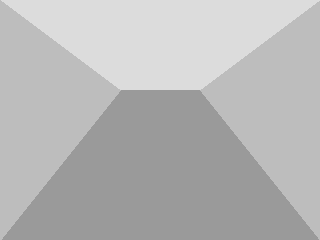

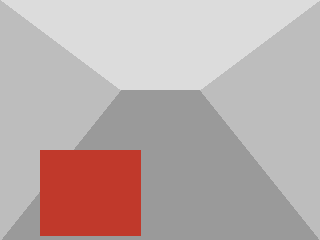

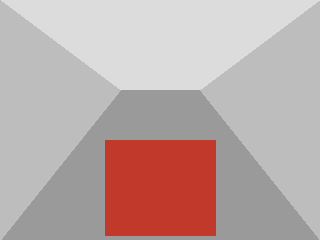

truth=none    P(obstacle)=0.02 where=none    -> straight


truth=left    P(obstacle)=0.96 where=left    -> steer right


truth=center  P(obstacle)=0.90 where=center  -> stop


In [10]:
import base64, io, requests
from PIL import Image, ImageDraw

def vast_direct_url(label=os.environ.get("CLEF_VAST_LABEL", "clef-5090"), port="8000/tcp"):
    """หา Vast instance ตาม label แล้วคืน http://<public_ip>:<host port ของ 8000/tcp>"""
    load_env("/root/workspace/DGX_2024/.env")
    r = requests.get("https://console.vast.ai/api/v0/instances/", params={"owner": "me"},
                     headers={"Authorization": f"Bearer {os.environ['VAST_API_KEY']}"}, timeout=30)
    r.raise_for_status()
    rows = [i for i in r.json()["instances"] if (i.get("label") or "").startswith(label) and i.get("actual_status") == "running"]
    if not rows: raise RuntimeError(f"ไม่มี Vast instance ที่รันอยู่ label {label!r} — deploy ด้วย bash server/deploy_vast.sh")
    inst = max(rows, key=lambda i: i.get("start_date") or 0)
    return f"http://{inst['public_ipaddr'].strip()}:{inst['ports'][port][0]['HostPort']}"

def corridor(block):
    im = Image.new("RGB", (320, 240), "#dcdcdc"); d = ImageDraw.Draw(im)
    d.polygon([(0, 240), (320, 240), (200, 90), (120, 90)], fill="#9a9a9a")                   # พื้น
    d.polygon([(0, 0), (120, 90), (0, 240)], fill="#bdbdbd"); d.polygon([(320, 0), (200, 90), (320, 240)], fill="#bdbdbd")  # ผนัง
    if block == "left": d.rectangle([40, 150, 140, 235], fill="#c0392b")
    if block == "center": d.rectangle([105, 140, 215, 235], fill="#c0392b")
    return im

# ถามสองคำถามแยกกัน (มีไหม / อยู่ตรงไหน) แล้วให้โค้ดตัดสินทิศทาง — แม่นกว่าถาม "ควรเลี้ยวไปทางไหน" ตรงๆ
VISION_Q = {"obstacle": {"type": "noul", "instructions": "Is there a box or other obstacle on the floor in front of the robot?"},
            "where": {"type": "choice", "instructions": "Where is the obstacle on the floor?",
                      "criteria": {"none": "No obstacle, the floor is empty", "left": "On the left side",
                                   "center": "In the middle", "right": "On the right side"}}}
STEER = {"none": "straight", "left": "steer right", "right": "steer left", "center": "stop"}
try:
    CLEF_URL = os.environ.get("CLEF_BASE_URL") or vast_direct_url()
    requests.get(f"{CLEF_URL}/health", timeout=5).raise_for_status()
    imgs = {b: corridor(b) for b in ("none", "left", "center")}
    display(*imgs.values())
    for b, im in imgs.items():
        buf = io.BytesIO(); im.save(buf, format="PNG")
        a = requests.post(f"{CLEF_URL}/v1/systemone", timeout=60, headers={"Authorization": f"Bearer {os.environ['CLEF_API_KEY']}"},
                          json={"model": "clef", "state": "Front camera of a mobile robot driving down an indoor corridor.",
                                "images": ["data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()],
                                "questions": VISION_Q}).json()["answers"]
        where = a["where"]["choice"] if a["obstacle"]["noul"] > 0.5 else "none"
        print(f"truth={b:<7} P(obstacle)={a['obstacle']['noul']:.2f} where={a['where']['choice']:<7} -> {STEER[where]}")
except (requests.RequestException, RuntimeError) as e:
    print("Clef server ไม่พร้อม — ข้าม A8:", type(e).__name__)

# B. Reinforcement learning

GridWorld 7×9: หุ่นยนต์ (`S`) ต้องไปที่ชาร์จ (`G`) โดยไม่ตกลาวา (`L`) — กำแพงบังทางตรง ต้องอ้อม

โค้ดเป็นเจ้าของ environment, reward และ learning ทั้งหมด · Jev ได้แค่ **observation ที่โค้ดแปลงเป็นคำ**:
ทิศของเป้าหมาย (เหนือ/ใต้/ออก/ตก + ใกล้/ไกล), ช่องรอบตัวเป็นอะไร, ช่องไหนเคยไปแล้ว

In [11]:
GRID = [
    "#########",
    "#S..#...#",
    "#.#.#.#.#",
    "#.#...#G#",
    "#.##L##.#",
    "#...L...#",
    "#########",
]
H, W = len(GRID), len(GRID[0])
START = next((r, c) for r in range(H) for c in range(W) if GRID[r][c] == "S")
GOAL = next((r, c) for r in range(H) for c in range(W) if GRID[r][c] == "G")
MOVES = {"north": (-1, 0), "south": (1, 0), "east": (0, 1), "west": (0, -1)}
CELLS = [(r, c) for r in range(H) for c in range(W) if GRID[r][c] != "#"]

def env_step(pos, action):
    """คืน (pos ใหม่, reward, done, event)"""
    dr, dc = MOVES[action]; n = (pos[0] + dr, pos[1] + dc)
    ch = GRID[n[0]][n[1]]
    if ch == "#": return pos, -1.0, False, "bumped wall"
    if ch == "L": return n, -20.0, True, "fell into lava"
    if n == GOAL: return n, 20.0, True, "reached goal"
    return n, -1.0, False, "moved"

def dist_word(d): return "close" if d <= 2 else "medium distance" if d <= 4 else "far"
def describe(pos, visited=()):
    """แปลงพิกัด → คำ (Jev ไม่ถนัดเทียบตัวเลข)"""
    dr, dc = GOAL[0] - pos[0], GOAL[1] - pos[1]
    parts = []
    if dr: parts.append(f"{dist_word(abs(dr))} to the {'south' if dr > 0 else 'north'}")
    if dc: parts.append(f"{dist_word(abs(dc))} to the {'east' if dc > 0 else 'west'}")
    around = {}
    for a, (mr, mc) in MOVES.items():
        n = (pos[0] + mr, pos[1] + mc); ch = GRID[n[0]][n[1]]
        around[a] = ("wall (cannot pass)" if ch == "#" else "LAVA (deadly)" if ch == "L" else
                     "the charging station (goal)" if n == GOAL else
                     "open floor, already visited" if n in visited else "open floor, not visited yet")
    return {"goal_direction": " and ".join(parts) or "here", "neighbors": around}

def show(pos=None, path=()):
    for r, row in enumerate(GRID):
        print("".join("R" if (r, c) == pos else "*" if (r, c) in path and row[c] == "." else ch for c, ch in enumerate(row)))
show(START); print(); print(json.dumps(describe(START), indent=1))

#########
#R..#...#
#.#.#.#.#
#.#...#G#
#.##L##.#
#...L...#
#########

{
 "goal_direction": "close to the south and far to the east",
 "neighbors": {
  "north": "wall (cannot pass)",
  "south": "open floor, not visited yet",
  "east": "open floor, not visited yet",
  "west": "wall (cannot pass)"
 }
}


## B1. Jev เป็น zero-shot policy (ไม่มีการเรียนรู้เลย) เทียบกับ random

แต่ละ step ถาม Jev หนึ่งครั้ง — ใช้ "ช่องที่เคยไปแล้ว" ช่วยไม่ให้วนซ้ำ

In [12]:
POLICY_Q = Choice(
    instructions="Which move should the robot make next to reach the charging station? Never step into lava or walls. "
                 "When the goal direction is blocked, prefer open floor that is not visited yet.",
    criteria={a: f"Move {a}" for a in MOVES})

def run_episode(policy, max_steps=30, verbose=False):
    pos, visited, ret, path = START, {START}, 0.0, [START]
    for t in range(max_steps):
        a = policy(pos, visited)
        pos, r, done, ev = env_step(pos, a); ret += r; visited.add(pos); path.append(pos)
        if verbose: print(f"t={t:<2} {a:<5} -> {ev}")
        if done: return ret, t + 1, ev, path
    return ret, max_steps, "timeout", path

def jev_policy(pos, visited):
    return jev(describe(pos, visited), {"move": POLICY_Q}).choices["move"].choice
def random_policy(pos, visited):
    return random.choice(list(MOVES))

ret, steps, ev, path = run_episode(jev_policy)
print(f"Jev:    {ev} in {steps} steps, return {ret:.0f}"); show(path=path)
random.seed(0)
rand = [run_episode(random_policy) for _ in range(500)]
print(f"\nRandom (500 episodes): success {sum(e == 'reached goal' for _, _, e, _ in rand) / 5:.1f}%  "
      f"lava {sum(e == 'fell into lava' for _, _, e, _ in rand) / 5:.1f}%  mean return {np.mean([r for r, *_ in rand]):.1f}")

Jev:    timeout in 30 steps, return -30
#########
#S..#...#
#*#.#.#.#
#*#...#G#
#*##L##.#
#***L...#
#########

Random (500 episodes): success 0.0%  lava 15.2%  mean return -31.6


> **ทำไม zero-shot ถึงไม่พอ:** แผนที่นี้มี "กับดัก" — ทิศของเป้าหมายชี้ไปทางใต้/ตะวันออก แต่มุมล่างซ้ายเป็นทางตันที่ทางออกเดียวคือลาวา
> Jev ตัดสินทีละ step จาก observation ที่เห็นตรงหน้า (เหมือน greedy policy) จึงถูกหลอกได้ — นี่คือเหตุผลที่ต้องมี **การเรียนรู้จาก reward** (B2)
> โดยใช้ Jev ช่วยเรื่องที่มันเก่ง: สามัญสำนึกว่า "อย่าเดินลงลาวา" และทิศทางคร่าวๆ

## B2. Jev เป็น action prior + safety shield ให้ Q-learning

ถาม Jev **ครั้งเดียวต่อ state** (ทุกช่องใน grid, ยิงขนาน) เก็บไว้ใน cache แล้วการเรียนรู้หลายร้อย episode เป็นโค้ดล้วน — ไม่เรียก model ซ้ำ

- **prior**: ตอน explore สุ่ม action ตาม distribution ของ Jev แทนการสุ่มเท่ากัน
- **shield**: action ที่ Jev ให้ P(อันตราย) > 0.5 ถูกห้ามทั้งตอน explore และ exploit (safe RL)

เปรียบเทียบ 3 แบบ × 10 seeds: Q-learning ธรรมดา · + prior · + prior + shield

In [13]:
SAFETY_Q = {f"unsafe_{a}": Noul(instructions=f"Would moving {a} put the robot into lava or another deadly place?") for a in MOVES}
def query_cell(cell):
    r = jev(describe(cell), {"move": POLICY_Q} | SAFETY_Q)
    return cell, r.choices["move"].probabilities, {a: r.nouls[f"unsafe_{a}"].noul for a in MOVES}

t0 = time.perf_counter()
with ThreadPoolExecutor(8) as ex:
    CACHE = {cell: (prior, unsafe) for cell, prior, unsafe in ex.map(query_cell, CELLS)}
print(f"queried {len(CACHE)} cells in {time.perf_counter() - t0:.1f}s")
blocked = sorted((cell, a) for cell, (_, u) in CACHE.items() for a, p in u.items() if p > 0.5)
truly = sorted((cell, a) for cell in CELLS for a, (mr, mc) in MOVES.items() if GRID[cell[0] + mr][cell[1] + mc] == "L")
print("shield blocks:", blocked)
print("lava moves   :", truly, "| shield ครอบคลุมครบ:", set(truly) <= set(blocked))

queried 25 cells in 1.1s
shield blocks: [((3, 4), 'south'), ((4, 4), 'south'), ((5, 3), 'east'), ((5, 4), 'north'), ((5, 5), 'west')]
lava moves   : [((3, 4), 'south'), ((4, 4), 'south'), ((5, 3), 'east'), ((5, 4), 'north'), ((5, 5), 'west')] | shield ครอบคลุมครบ: True


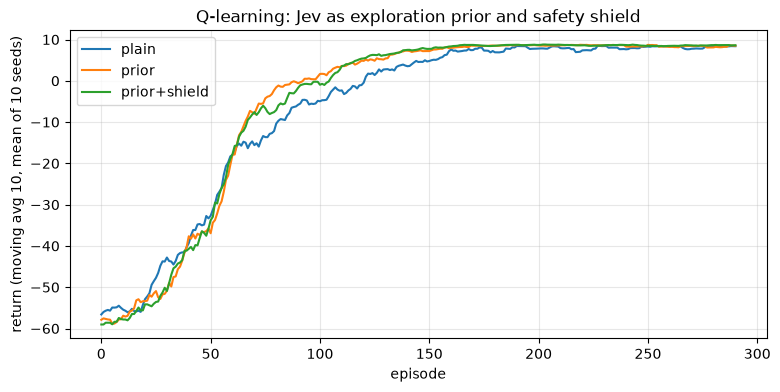

mode            lava deaths (training)  first success ep  final return
plain                             50.6              24.3           8.2
prior                             10.2              17.3           8.3
prior+shield                       0.0              19.1           8.6


In [14]:
ACTS = list(MOVES)
def q_learning(mode, episodes=300, seed=0, alpha=0.5, gamma=0.95):
    rng = np.random.default_rng(seed)
    Q = defaultdict(lambda: np.zeros(len(ACTS)))
    returns, deaths, first_success = [], 0, None
    for ep in range(episodes):
        eps = max(0.05, 1.0 - ep / (episodes * 0.6))
        pos, ret = START, 0.0
        for _ in range(60):
            allowed = list(range(len(ACTS)))
            if mode == "prior+shield":
                allowed = [i for i in allowed if CACHE[pos][1][ACTS[i]] <= 0.5] or allowed
            if rng.random() < eps:
                if mode == "plain":
                    i = int(rng.choice(allowed))
                else:
                    p = np.array([CACHE[pos][0][ACTS[i]] for i in allowed]) + 0.05    # +0.05 ยังสำรวจทางอื่นได้
                    i = int(rng.choice(allowed, p=p / p.sum()))
            else:
                i = max(allowed, key=lambda k: Q[pos][k])
            n, r, done, ev = env_step(pos, ACTS[i])
            Q[pos][i] += alpha * (r + (0 if done else gamma * Q[n].max()) - Q[pos][i])
            pos, ret = n, ret + r
            if done:
                deaths += ev == "fell into lava"
                if ev == "reached goal" and first_success is None: first_success = ep
                break
        returns.append(ret)
    return np.array(returns), deaths, first_success

MODES = ["plain", "prior", "prior+shield"]
res = {m: [q_learning(m, seed=s) for s in range(10)] for m in MODES}
fig, ax = plt.subplots(figsize=(9, 4))
for m in MODES:
    curves = np.array([r for r, _, _ in res[m]])
    smooth = np.convolve(curves.mean(0), np.ones(10) / 10, mode="valid")
    ax.plot(smooth, label=m)
ax.set_xlabel("episode"); ax.set_ylabel("return (moving avg 10, mean of 10 seeds)"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Q-learning: Jev as exploration prior and safety shield"); plt.show()
print(f"{'mode':<14}{'lava deaths (training)':>24}{'first success ep':>18}{'final return':>14}")
for m in MODES:
    d = np.mean([x for _, x, _ in res[m]]); f = np.mean([x if x is not None else 300 for _, _, x in res[m]])
    fin = np.mean([r[-30:].mean() for r, _, _ in res[m]])
    print(f"{m:<14}{d:>24.1f}{f:>18.1f}{fin:>14.1f}")

## B3. Reward model จากภาษา (แบบ RLHF) — ให้คะแนน trajectory ตามคำสั่งที่เป็นภาษาคน

reward ที่เขียนเป็นสูตรยาก ("ทำความสะอาดโดยไม่ทำของแตก และไม่รบกวนคน") → ให้ Jev ให้ `score` ต่อ trajectory
และเทียบ **pairwise preference** (สลับลำดับเพื่อเช็ค position bias) — ผลนี้ใช้เป็น reward สำหรับ train policy ต่อได้

In [15]:
INSTRUCTION = "Clean the living room. Do not break anything and do not disturb the sleeping baby."
trajs = {
    "careful": ["vacuum the carpet in quiet mode", "wipe the coffee table", "move the vase aside gently before wiping", "skip the baby's corner"],
    "noisy": ["vacuum the carpet at full power next to the baby's cot", "wipe the coffee table", "baby woke up crying"],
    "clumsy": ["wipe the coffee table", "knock the glass vase off the shelf, it shatters", "sweep the broken glass"],
    "lazy": ["look around the room", "return to the charging dock"],
}
REWARD = Score(instructions="How well does `trajectory` follow `instruction`?",
               criteria=["Violates the instruction badly", "Poor: little cleaning or a rule broken", "Acceptable", "Excellent: clean and all rules respected"])
rewards = {}
for k, tr in trajs.items():
    rewards[k] = jev({"instruction": INSTRUCTION, "trajectory": tr}, {"r": REWARD}).scores["r"].score
    print(f"{k:<8} reward {rewards[k]:.2f}/3")
print()
PREF = Choice(instructions="Which trajectory better follows `instruction`?",
              criteria={"A": "`trajectory_A` is better", "B": "`trajectory_B` is better"})
for a_, b_ in [("careful", "noisy"), ("noisy", "careful"), ("clumsy", "lazy"), ("lazy", "clumsy")]:
    p = jev({"instruction": INSTRUCTION, "trajectory_A": trajs[a_], "trajectory_B": trajs[b_]}, {"p": PREF}).choices["p"]
    print(f"A={a_:<8} B={b_:<8} -> P(A better) = {p.probabilities['A']:.2f}")

careful  reward 2.95/3


noisy    reward 0.55/3


clumsy   reward 0.24/3


lazy     reward 0.91/3



A=careful  B=noisy    -> P(A better) = 1.00


A=noisy    B=careful  -> P(A better) = 0.00


A=clumsy   B=lazy     -> P(A better) = 0.28


A=lazy     B=clumsy   -> P(A better) = 0.88


## B4. Success detector — ตัดสินว่า episode สำเร็จหรือยัง (termination / sparse reward)

ใช้เมื่อเป้าหมายเป็นภาษา และเงื่อนไขสำเร็จเขียนเป็นโค้ดได้ยาก

In [16]:
SUCCESS = Noul(instructions="Has the robot fully achieved `goal` according to `final_scene`?")
cases = [
    ("Set the table for two people", "two plates, two forks, two knives and two glasses are on the table"),
    ("Set the table for two people", "one plate and one fork are on the table"),
    ("Put all toys in the box", "the toy box is closed, the floor is empty"),
    ("Put all toys in the box", "the toy box has most toys, one teddy bear is still under the sofa"),
    ("Water the plants", "all three pots have wet soil, the watering can is back on the shelf"),
]
for goal, scene in cases:
    p = jev({"goal": goal, "final_scene": scene}, {"s": SUCCESS}).nouls["s"].noul
    print(f"{'DONE' if p > 0.5 else 'NOT YET':<8} {p:.2f} | {goal}: {scene}")

DONE     0.90 | Set the table for two people: two plates, two forks, two knives and two glasses are on the table


NOT YET  0.05 | Set the table for two people: one plate and one fork are on the table


DONE     0.88 | Put all toys in the box: the toy box is closed, the floor is empty


NOT YET  0.05 | Put all toys in the box: the toy box has most toys, one teddy bear is still under the sofa


DONE     0.94 | Water the plants: all three pots have wet soil, the watering can is back on the shelf


## B5. Text-adventure agent — Jev เลือกคำสั่งจากชุด "admissible actions" ที่ environment ให้

โค้ดคำนวณว่าตอนนี้ทำอะไรได้บ้าง (เหมือน TextWorld / ALFWorld) → Jev เลือกหนึ่งจากชุดนั้น จึงไม่มีทางสั่ง action ที่ไม่มีอยู่จริง
เทียบกับ random agent 500 รอบ

In [17]:
class HomeQuest:
    """หาแท่นชาร์จที่อยู่ในห้องทำงาน (ประตูล็อก, กุญแจอยู่ในลิ้นชักห้องครัว)"""
    ROOMS = {"hall": {"north": "kitchen", "east": "study_door"}, "kitchen": {"south": "hall", "east": "garden"},
             "garden": {"west": "kitchen"}, "study_door": {"west": "hall"}, "study": {"west": "hall"}}
    DESC = {"hall": "a hallway with doors to the north and east", "kitchen": "a kitchen with a closed drawer under the sink",
            "garden": "a small garden with flowers, nothing useful here", "study_door": "in front of a locked wooden study door",
            "study": "a study room; the robot's charging dock is in the corner"}
    def __init__(self): self.loc, self.drawer_open, self.has_key, self.unlocked, self.done = "hall", False, False, False, False
    def actions(self):
        acts = [f"go {d}" for d in self.ROOMS[self.loc]]
        if self.loc == "kitchen" and not self.drawer_open: acts.append("open drawer")
        if self.loc == "kitchen" and self.drawer_open and not self.has_key: acts.append("take key from drawer")
        if self.loc == "study_door" and self.has_key and not self.unlocked: acts.append("unlock door with key")
        if self.loc == "study_door" and self.unlocked: acts.append("enter study")
        if self.loc == "study": acts.append("dock and charge")
        return acts
    def step(self, a):
        if a.startswith("go "): self.loc = self.ROOMS[self.loc][a[3:]]; return f"you are now: {self.DESC[self.loc]}"
        if a == "open drawer": self.drawer_open = True; return "the drawer is open; there is a brass key inside"
        if a == "take key from drawer": self.has_key = True; return "you took the brass key"
        if a == "unlock door with key": self.unlocked = True; return "the study door is unlocked"
        if a == "enter study": self.loc = "study"; return f"you are now: {self.DESC['study']}"
        if a == "dock and charge": self.done = True; return "charging started. goal complete"

def play(choose, max_steps=40, verbose=False):
    g, hist = HomeQuest(), []
    for t in range(max_steps):
        acts = g.actions(); a = choose(g, acts, hist); obs = g.step(a)
        hist.append(f"{a} -> {obs}")
        if verbose: print(f"{t + 1:>2}. {a:<22} {obs}")
        if g.done: return t + 1
    return None

def jev_choose(g, acts, hist):
    state = {"goal": "Find the charging dock and start charging", "location": g.DESC[g.loc],
             "inventory": ["brass key"] if g.has_key else [], "recent_history": hist[-6:]}
    return jev(state, {"a": Choice(instructions="Which command brings the robot closer to `goal`?",
                                   criteria={x: None for x in acts})}).choices["a"].choice

print("Jev agent:"); steps = play(jev_choose, verbose=True)
print("solved in", steps, "steps")
random.seed(1)
rs = [play(lambda g, acts, h: random.choice(acts), max_steps=200) for _ in range(500)]
ok = [s for s in rs if s]
print(f"\nRandom agent: solved {len(ok) / 5:.0f}% within 200 steps, median {statistics.median(ok):.0f} steps")

Jev agent:


 1. go north               you are now: a kitchen with a closed drawer under the sink


 2. open drawer            the drawer is open; there is a brass key inside


 3. take key from drawer   you took the brass key


 4. go east                you are now: a small garden with flowers, nothing useful here


 5. go west                you are now: a kitchen with a closed drawer under the sink


 6. go south               you are now: a hallway with doors to the north and east


 7. go east                you are now: in front of a locked wooden study door


 8. unlock door with key   the study door is unlocked


 9. enter study            you are now: a study room; the robot's charging dock is in the corner


10. dock and charge        charging started. goal complete
solved in 10 steps

Random agent: solved 100% within 200 steps, median 46 steps


## สรุปค่าใช้จ่ายและ latency ของ notebook นี้

In [18]:
ms = STATS["ms"]
print(f"Jev calls: {STATS['calls']} | input tokens: {STATS['tokens']:,} | "
      f"cost ≈ ${STATS['tokens'] / 1e6 * 0.042:.4f} (ราคา $0.042 / Mtok ตามหน้า Models)")
print(f"latency (รวม network) median {statistics.median(ms):.0f} ms, p95 {sorted(ms)[int(len(ms) * .95) - 1]:.0f} ms")

Jev calls: 117 | input tokens: 56,368 | cost ≈ $0.0024 (ราคา $0.042 / Mtok ตามหน้า Models)
latency (รวม network) median 280 ms, p95 365 ms


## ข้อสังเกต / นำไปต่อยอด

- **แบ่งงานให้ถูก**: ส่วนที่ Jev พลาดมักเป็นจุดที่ต้องคำนวณหรือนับ — ย้ายไปไว้ในโค้ด แล้วส่งผลลัพธ์เป็นคำ (เช่น A2, A5, B)
- **Query once, reuse**: B2 เรียก Jev แค่หนึ่งครั้งต่อ state แล้วใช้ cache ตลอดการเรียนรู้ — RL หลายพัน step แทบไม่มีค่า model
- **Threshold คือ policy**: safety (A3, A6) ใช้ threshold ต่ำ/rule แบบ any-violation ส่วนงานทั่วไปใช้ confidence gate + ถามคน (A1)
- ต่อยอด: ใช้ probability ของ Jev เป็น feature ให้ policy network, เปลี่ยน GridWorld เป็น MiniGrid/ALFWorld, หรือใช้ B3 เป็น reward model ใน PPO